# 04 · Maintenance policy: what should the planner do, and what is it worth?

**Question:** turning the risk model's probabilities into workshop actions, how much does the
fleet save compared with today's run-to-failure, with calling every truck in, and with the
fixed-age rule? How robust is that to the cost of a breakdown and to limited workshop capacity?
And, evaluated **once** on the untouched test set: does it hold?

Data: SCANIA Component X dataset, Swedish National Data Service,
https://doi.org/10.5878/bnh5-ka77, CC BY 4.0.

Structure:
- Sections 1–4 use **validation only**: the cross-fitted probabilities from notebook 03
  (`data/processed/validation_scores.csv`) and the baselines from notebook 02.
- Section 5 **freezes** every choice and writes it to disk.
- Section 6 is the **one-time test evaluation**; nothing is tuned after it. Sections 7–8 only
  re-express and export the test results.

Planner actions (CLAUDE.md): 4 = Call in now, 3 = Book within 12 steps, 2 = Book within 24 steps,
1 = Plan within 48 steps, 0 = No action. Costs are relative units set by Scania experts, not SEK;
any SEK or downtime figure below is an **illustrative assumption**.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import duckdb
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")
import shap

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import viz
from costs import ACTIONS, CLASSES, COST, expected_cost, expected_cost_decision
from risk_model import AGE_IDX, INPUTS, SPEC_COLS, apply_calibrator, due_log_odds, model_matrix, pretty

viz.apply_style()
FIGS = ROOT / "docs" / "figures"
PROCESSED = ROOT / "data" / "processed"
SEED = 2024
pd.set_option("display.float_format", "{:,.1f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

# Validation inputs (no database access before section 6).
val = pd.read_csv(PROCESSED / "validation_scores.csv")
P_val = val[[f"p{k}" for k in CLASSES]].to_numpy()
y_val, age_val = val.actual_class.to_numpy(), val.time_step.to_numpy()
age_rule = pd.read_csv(PROCESSED / "fixed_age_rule.csv")
assert len(val) == 5046

In [2]:
def fixed_age_rule(age):
    '''Baseline (b) from notebook 02: class per 5-step age bin (monotone; tuned on validation).'''
    edges = age_rule.age_from.to_numpy()
    return age_rule["class"].to_numpy()[np.clip(np.digitize(age, edges) - 1, 0, len(edges) - 1)]


def age_band_rule(age):
    '''Stricter age-only bar from notebook 02: call in trucks aged 100-250, no action otherwise.'''
    return np.where((age >= 100) & (age < 250), 4, 0)


def model_policy(P, cost=COST):
    return expected_cost_decision_m(P, cost)


def expected_cost_decision_m(P, cost):
    return (np.asarray(P) @ cost).argmin(axis=1)


def metrics(y, d, cost=COST):
    y, d = np.asarray(y), np.asarray(d)
    due = y > 0
    n = len(y)
    return {
        "cost_per_1000": 1000 * cost[y, d].sum() / n,
        "repairs_due": int(due.sum()),
        "caught_in_time": int((due & (d >= y)).sum()),
        "late": int((due & (d > 0) & (d < y)).sum()),
        "missed": int((due & (d == 0)).sum()),
        "share_caught_in_time": (due & (d >= y)).sum() / max(due.sum(), 1),
        "unnecessary_call_ins": int((~due & (d > 0)).sum()),
        "call_ins_per_1000": 1000 * (d > 0).mean(),
        "unnecessary_per_1000": 1000 * (~due & (d > 0)).mean(),
    }


def policy_table(y, age, P, extra=None):
    pols = {
        "Run-to-failure": np.zeros_like(y),
        "Call everyone in now": np.full_like(y, 4),
        "Fixed-age rule (b)": fixed_age_rule(age),
        "Age bands (validation-tuned bar)": age_band_rule(age),
        "Model policy (expected cost)": model_policy(P),
    }
    pols.update(extra or {})
    t = pd.DataFrame({k: metrics(y, d) for k, d in pols.items()}).T
    ints = ["repairs_due", "caught_in_time", "late", "missed", "unnecessary_call_ins"]
    t[ints] = t[ints].astype(int)
    return t, pols


def show(table):
    # display helper: shares as percentages, other floats rounded
    out = table.copy()
    out["share_caught_in_time"] = out["share_caught_in_time"].map("{:.1%}".format)
    return out.round(1)

## 1. The expected-cost decision rule

For a truck with class probabilities $P(0), \dots, P(4)$ (calibrated, notebook 03), the expected
cost of action $d$ is

$$E[\text{cost} \mid d] = \sum_{k=0}^{4} P(k)\,\text{COST}[k][d],$$

and the rule picks the action with the **lowest expected cost**. This is the Bayes decision rule:
if the probabilities are calibrated, no other rule using the same information has a lower average
cost. It is implemented in `src/costs.py` (`expected_cost_decision`) as one matrix product,
`P @ COST`, followed by an argmin per truck. A worked example for one validation truck:

In [3]:
due = 1 - P_val[:, 0]
i = int(np.argmin(np.abs(due - 0.05)))            # a truck with about a 5% chance of a repair due
ex = pd.DataFrame({"P(actual = k)": P_val[i]}, index=pd.Index(CLASSES, name="k"))
ec = pd.DataFrame({"action": [ACTIONS[d] for d in CLASSES],
                   "expected cost": expected_cost(P_val[i:i + 1])[0]}, index=pd.Index(CLASSES, name="d"))
print(f"truck {val.vehicle_id[i]}, age {age_val[i]:.0f}, P(repair due within 48 steps) = {due[i]:.1%}")
display(ex.T.round(4))
display(ec.round(2))
print(f"-> rule picks: {ACTIONS[int(ec['expected cost'].idxmin())]}")

d_val = model_policy(P_val)
called, idle = due[d_val > 0], due[d_val == 0]
print(f"\nBreak-even in practice: the model calls in every validation truck with P(due) >= {called.min():.2%} "
      f"and leaves alone every truck with P(due) <= {idle.max():.2%}")

truck 29425, age 141, P(repair due within 48 steps) = 5.0%


k,0,1,2,3,4
P(actual = k),0.9,0.0,0.0,0.0,0.0


,action,expected cost
d,,
0,No action,18.6
1,Plan within 48 steps,19.5
2,Book within 24 steps,14.1
3,Book within 12 steps,12.8
4,Call in now,9.7


-> rule picks: Call in now

Break-even in practice: the model calls in every validation truck with P(due) >= 2.21% and leaves alone every truck with P(due) <= 3.59%


**Interpretation.** The example truck has only a 5.0% chance of a repair being due within 48 steps, yet calling it in now is the cheapest action (expected cost 9.7, against 18.6 for no action). An unnecessary call-in costs 10, while a missed repair costs 200–500, so a risk of a few percent is already enough. In practice every validation truck with P(due) ≥ 2.2% is called in, and every truck at or below 3.6% may be left alone. The two ranges overlap because the threshold depends on *how urgent* the risk is: missing a class 1 repair costs 200, missing a class 4 repair costs 500.

## 2. The policies on validation

The model policy uses the **cross-fitted** calibrated probabilities from notebook 03 (each truck
scored by calibrators that did not see it). The fixed-age rule and the age bands were tuned on
validation in notebook 02, so their validation numbers are in-sample. All four metrics are per the
definitions:

- **caught in time:** a repair is due (class ≥ 1) and the action is at least as urgent as needed;
- **late:** an action was taken but too late; **missed:** no action;
- **unnecessary call-in:** class 0 and any action.

In [4]:
val_table, val_pols = policy_table(y_val, age_val, P_val)
# consistency with notebooks 02 and 03
assert (val_pols["Model policy (expected cost)"] == val.recommended_action).all()
assert round(val_table.loc["Model policy (expected cost)", "cost_per_1000"]) == 6538
assert round(val_table.loc["Fixed-age rule (b)", "cost_per_1000"]) == 9702
assert round(val_table.loc["Age bands (validation-tuned bar)", "cost_per_1000"]) == 8109
show(val_table)

,cost_per_1000,repairs_due,caught_in_time,late,missed,share_caught_in_time,unnecessary_call_ins,call_ins_per_1000,unnecessary_per_1000
Run-to-failure,"11,375.3",136,0,0,136,0.0%,0,0.0,0.0
Call everyone in now,"9,822.8",136,136,0,0,100.0%,4910,"1,000.0",973.0
Fixed-age rule (b),"9,701.9",136,136,0,0,100.0%,4849,987.9,961.0
Age bands (validation-tuned bar),"8,109.4",136,99,0,37,72.8%,2530,521.0,501.4
Model policy (expected cost),"6,538.4",136,101,1,34,74.3%,1936,403.9,383.7


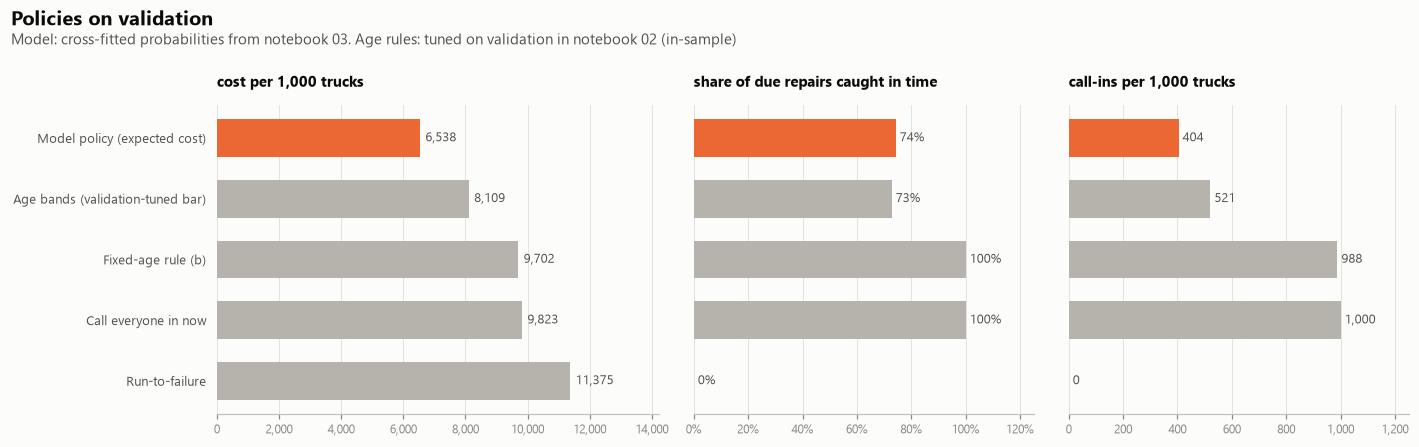

In [5]:
def policy_bars(table, title, subtitle, name):
    t = table.sort_values("cost_per_1000", ascending=False)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True,
                             gridspec_kw={"width_ratios": [1.3, 1, 1]})
    cols = [viz.ORANGE if "Model policy" in p and "no age" not in p else viz.GREY_LIGHT for p in t.index]
    specs = [("cost_per_1000", "cost per 1,000 trucks", "{:,.0f}"),
             ("share_caught_in_time", "share of due repairs caught in time", "{:.0%}"),
             ("call_ins_per_1000", "call-ins per 1,000 trucks", "{:,.0f}")]
    for ax, (col, label, fmt) in zip(axes, specs):
        ax.barh(range(len(t)), t[col], color=cols, height=0.62)
        for j, v in enumerate(t[col]):
            ax.text(v + t[col].max() * 0.015, j, fmt.format(v), va="center", fontsize=8.5, color=viz.INK2)
        ax.set_xlim(0, t[col].max() * 1.25)
        ax.set_title(label, fontsize=10)
        ax.grid(axis="x"); ax.grid(axis="y", visible=False)
        ax.tick_params(axis="x", labelsize=8)
        if col == "share_caught_in_time":
            ax.xaxis.set_major_formatter(viz.PCT)
        else:
            ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
    axes[0].set_yticks(range(len(t)), t.index)
    axes[0].tick_params(axis="y", colors=viz.INK2)
    viz.suptitle(fig, title, subtitle)
    fig.tight_layout()
    viz.save(fig, name, FIGS)
    plt.show()


policy_bars(val_table, "Policies on validation",
            "Model: cross-fitted probabilities from notebook 03. Age rules: tuned on validation in notebook 02 (in-sample)",
            "04_policies_validation")

**Interpretation.** Calling everyone in catches all 136 due repairs but makes 4,910 unnecessary call-ins. The fixed-age rule is nearly the same policy (988 call-ins per 1,000). The model policy catches 101 repairs in time (plus 1 late) and misses 34, with **2,974 fewer unnecessary call-ins**: that is how it gets to 6,538 per 1,000 trucks, two thirds of the call-everyone cost. Against the validation-tuned age bands it catches about the same number of repairs (101 vs 99) with 22% fewer call-ins (404 vs 521 per 1,000).

## 3. Sensitivity: what if a missed repair costs more or less?

The expert cost matrix may be wrong. Every cell **below the diagonal** (missed or late repairs:
200–500) is multiplied by *m* from 0.25 to 4; the call-in costs (7–10) stay fixed. Two versions
of the model policy:

- **re-optimised:** the planner knows the new costs and re-runs the expected-cost rule with them
  (same probabilities). This answers *"how should the policy react if breakdowns cost more?"*
- **decisions fixed at m = 1:** today's decisions, re-priced. This answers
  *"how wrong can our cost estimate be before today's policy stops paying?"*

The baselines' decisions don't depend on costs, so they are only re-priced.

In [6]:
MULTS = [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0, 2.8, 4.0]
lower = np.tril(np.ones((5, 5), bool), -1)
rows = []
for m in MULTS:
    cost_m = np.where(lower, COST * m, COST)
    decisions = {
        "Model, re-optimised": expected_cost_decision_m(P_val, cost_m),
        "Model, decisions fixed at m = 1": val_pols["Model policy (expected cost)"],
        "Call everyone in now": val_pols["Call everyone in now"],
        "Fixed-age rule (b)": val_pols["Fixed-age rule (b)"],
        "Run-to-failure": val_pols["Run-to-failure"],
    }
    for name, d in decisions.items():
        rows.append({"miss_cost_multiplier": m, "policy": name, **metrics(y_val, d, cost_m)})
sens = pd.DataFrame(rows)
sens.pivot(index="miss_cost_multiplier", columns="policy", values="cost_per_1000").rename(index=lambda m: f"{m:g}×").round(0)

policy,Call everyone in now,Fixed-age rule (b),"Model, decisions fixed at m = 1","Model, re-optimised",Run-to-failure
miss_cost_multiplier,,,,,
0.25×,"9,823.0","9,702.0","4,547.0","2,696.0","2,844.0"
0.35×,"9,823.0","9,702.0","4,812.0","3,585.0","3,981.0"
0.5×,"9,823.0","9,702.0","5,211.0","4,555.0","5,688.0"
0.7×,"9,823.0","9,702.0","5,742.0","5,711.0","7,963.0"
1×,"9,823.0","9,702.0","6,538.0","6,538.0","11,375.0"
1.4×,"9,823.0","9,702.0","7,601.0","7,996.0","15,925.0"
2×,"9,823.0","9,702.0","9,194.0","9,327.0","22,751.0"
2.8×,"9,823.0","9,702.0","11,318.0","9,676.0","31,851.0"
4×,"9,823.0","9,702.0","14,505.0","10,385.0","45,501.0"


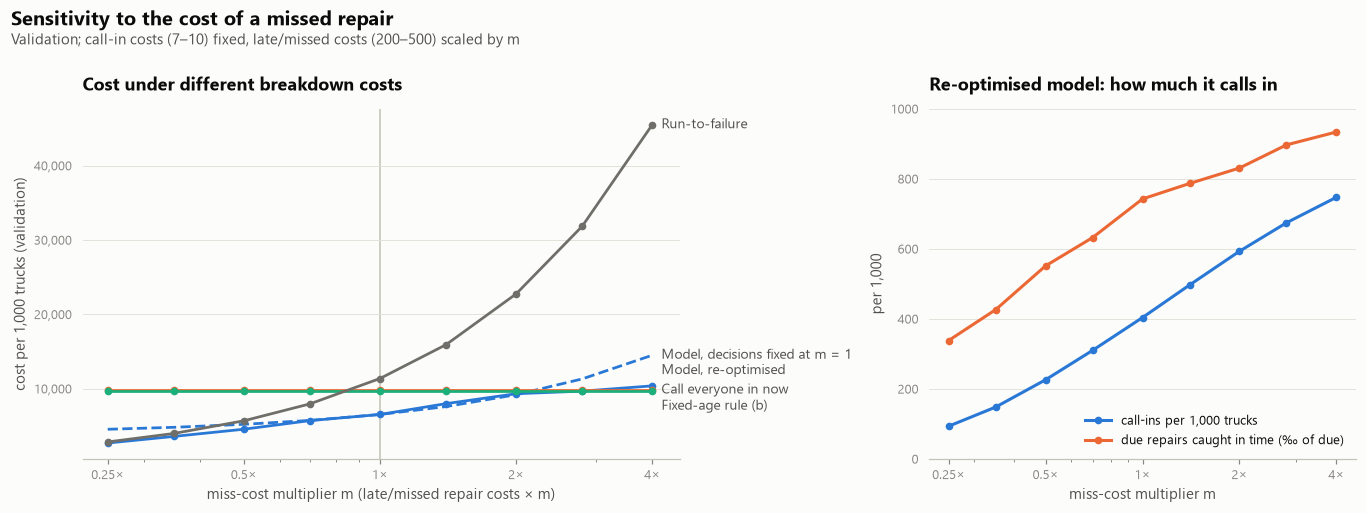

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
style = {"Model, re-optimised": (viz.BLUE, "-"), "Model, decisions fixed at m = 1": (viz.BLUE, "--"),
         "Call everyone in now": (viz.ORANGE, "-"), "Fixed-age rule (b)": (viz.AQUA, "-"),
         "Run-to-failure": (viz.GREY_DARK, "-")}
for name, (color, ls) in style.items():
    s = sens[sens.policy == name].set_index("miss_cost_multiplier").cost_per_1000
    ax.plot(s.index, s.values, color=color, ls=ls, lw=1.8, marker="o" if ls == "-" else None, markersize=4)
    dy = {"Model, re-optimised": 10, "Call everyone in now": 0, "Fixed-age rule (b)": -10}.get(name, 0)
    viz.label_end(ax, s.index[-1], s.values[-1], name, dy=dy)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25×", "0.5×", "1×", "2×", "4×"])
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.axvline(1, color=viz.AXIS, lw=1, zorder=0)
ax.set_xlim(0.22, 4.6)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("miss-cost multiplier m (late/missed repair costs × m)")
ax.set_ylabel("cost per 1,000 trucks (validation)")
ax.set_title("Cost under different breakdown costs")

ax = axes[1]
s = sens[sens.policy == "Model, re-optimised"].set_index("miss_cost_multiplier")
ax.plot(s.index, s.call_ins_per_1000, color=viz.BLUE, marker="o", label="call-ins per 1,000 trucks")
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25×", "0.5×", "1×", "2×", "4×"])
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_ylim(0, 1000)
ax2_vals = s.share_caught_in_time * 1000
ax.plot(s.index, ax2_vals, color=viz.ORANGE, marker="o", label="due repairs caught in time (‰ of due)")
ax.set_xlabel("miss-cost multiplier m")
ax.set_ylabel("per 1,000")
ax.set_title("Re-optimised model: how much it calls in")
ax.legend(loc="lower right", fontsize=8.5)
viz.suptitle(fig, "Sensitivity to the cost of a missed repair",
             "Validation; call-in costs (7–10) fixed, late/missed costs (200–500) scaled by m")
fig.tight_layout()
viz.save(fig, "04_miss_cost_sensitivity", FIGS)
plt.show()

**Interpretation.**

- **Today's decisions, re-priced (dashed line):** they stay cheaper than calling everyone in until the true cost of a missed repair reaches about **2× the expert matrix** (9,194 vs 9,823 at 2×), then lose (11,318 at 2.8×). If the experts *overestimated* the miss cost, the policy gains even more.
- **Re-optimised for each multiplier:** the policy calls in more trucks as misses get dearer (from 92 to 747 per 1,000) and catches more repairs (from 34% to 93% of those due). It beats calling everyone in up to about 2.8× (9,676 vs 9,823) and loses at 4× (10,385). At 0.25× it almost ties run-to-failure (2,696 vs 2,844): when misses are cheap, doing little is right.
- **Re-optimising is not always better than keeping today's decisions** (at 1.4×: 7,996 vs 7,601; at 2×: 9,327 vs 9,194). A higher miss cost moves the call-in threshold into the 1–2% risk range, where the calibration rests on few repairs and is less accurate. The expected-cost rule is only as good as the probabilities it is given.
- **Practical reading:** the model policy pays as long as a breakdown costs no more than about 2–3× what Scania's experts put in the matrix. Beyond that, calling every truck in is as good and much simpler.

## 4. Workshop capacity: only K call-ins per 1,000 trucks

The unconstrained policy calls in about 40% of the fleet, which a real workshop may not have
room for. With capacity for **K call-ins per 1,000 trucks**, the planner should call in the trucks
where calling in **saves the most expected cost**:

$$\text{saving} = E[\text{cost} \mid \text{no action}] - E[\text{cost} \mid \text{call in now}],$$

calling in the top K and taking no action for the rest. Trucks with a negative saving are never
called in, so above the unconstrained policy's volume the curve flattens. For comparison:
**K random trucks**, and **K oldest trucks** (the wear-out instinct: "service the oldest first").

In [8]:
ec_val = expected_cost(P_val)
saving = ec_val[:, 0] - ec_val[:, 4]
n = len(y_val)
cost_none, cost_call = COST[y_val, 0], COST[y_val, 4]
K_GRID = np.arange(0, 1001, 25)
rows = []
for K in K_GRID:
    k = int(round(K / 1000 * n))
    for name, order in [("Model: highest expected saving", np.argsort(-saving)),
                        ("Oldest trucks first", np.argsort(-age_val, kind="stable"))]:
        d = np.zeros(n, int)
        chosen = order[:k]
        if name.startswith("Model"):
            chosen = chosen[saving[chosen] > 0]
        d[chosen] = 4
        rows.append({"K_per_1000": K, "policy": name, **metrics(y_val, d)})
    frac = k / n                     # random K: expected cost and catches, analytically
    rows.append({"K_per_1000": K, "policy": "Random trucks",
                 "cost_per_1000": 1000 * (frac * cost_call.sum() + (1 - frac) * cost_none.sum()) / n,
                 "share_caught_in_time": frac, "call_ins_per_1000": K})
cap = pd.DataFrame(rows)
cap.pivot(index="K_per_1000", columns="policy", values="cost_per_1000").iloc[::4].round(0)

policy,Model: highest expected saving,Oldest trucks first,Random trucks
K_per_1000,,,
0,"11,375.0","11,375.0","11,375.0"
100,"8,088.0","11,853.0","11,220.0"
200,"7,193.0","12,510.0","11,065.0"
300,"6,725.0","12,926.0","10,910.0"
400,"6,476.0","12,457.0","10,754.0"
500,"6,502.0","11,503.0","10,599.0"
600,"6,502.0","11,495.0","10,444.0"
700,"6,502.0","10,280.0","10,289.0"
800,"6,502.0","9,914.0","10,133.0"


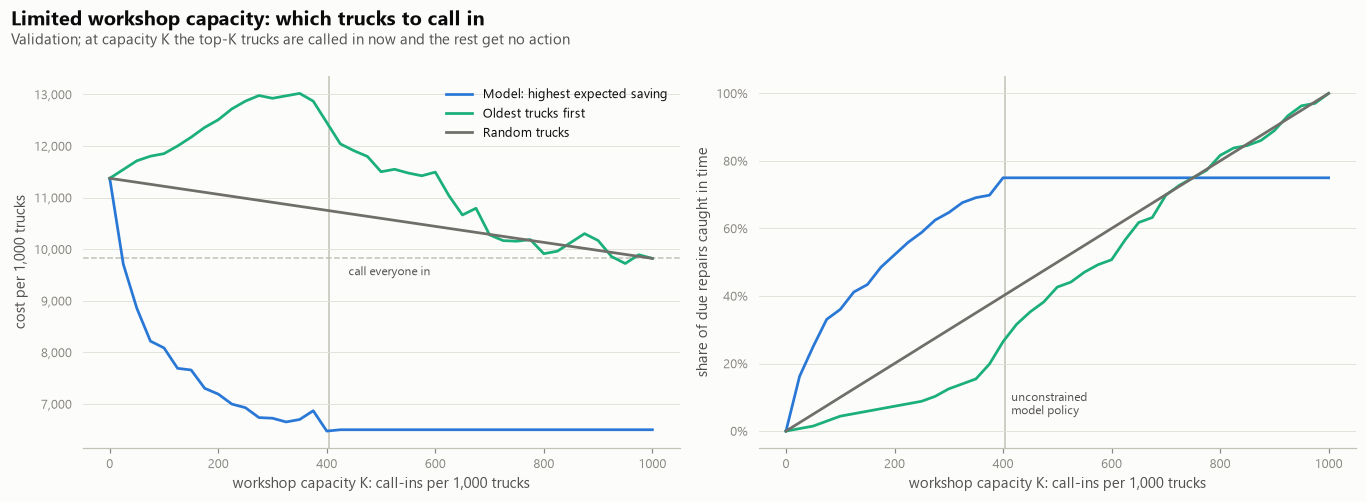

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
cstyle = {"Model: highest expected saving": viz.BLUE, "Oldest trucks first": viz.AQUA, "Random trucks": viz.GREY_DARK}
for ax, col, ylabel in [(axes[0], "cost_per_1000", "cost per 1,000 trucks"),
                        (axes[1], "share_caught_in_time", "share of due repairs caught in time")]:
    for name, color in cstyle.items():
        s = cap[cap.policy == name].set_index("K_per_1000")[col]
        ax.plot(s.index, s.values, color=color, lw=1.8, label=name)
    ax.set_xlabel("workshop capacity K: call-ins per 1,000 trucks")
    ax.set_ylabel(ylabel)
unc = val_table.loc["Model policy (expected cost)"]
axes[0].axhline(val_table.loc["Call everyone in now", "cost_per_1000"], color=viz.AXIS, lw=1, ls="--", zorder=0)
axes[0].annotate("call everyone in", (440, val_table.loc["Call everyone in now", "cost_per_1000"]),
                 xytext=(0, -11), textcoords="offset points", ha="left", fontsize=8, color=viz.INK2)
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(viz.PCT)
axes[0].legend(loc="upper right", fontsize=8.5)
for ax in axes:
    ax.axvline(unc.call_ins_per_1000, color=viz.AXIS, lw=1, zorder=0)
axes[1].annotate("unconstrained\nmodel policy", (unc.call_ins_per_1000, 0.05), xytext=(4, 0),
                 textcoords="offset points", fontsize=8, color=viz.INK2)
viz.suptitle(fig, "Limited workshop capacity: which trucks to call in",
             "Validation; at capacity K the top-K trucks are called in now and the rest get no action")
fig.tight_layout()
viz.save(fig, "04_capacity", FIGS)
plt.show()

In [10]:
pick = cap[cap.K_per_1000.isin([50, 100, 200, 300])].pivot(
    index="K_per_1000", columns="policy", values=["cost_per_1000", "share_caught_in_time"])
pick.apply(lambda c: c.map("{:.1%}".format) if c.name[0] == "share_caught_in_time" else c.map("{:,.0f}".format))

cost_per_1000                                             share_caught_in_time                                  
policy     Model: highest expected saving Oldest trucks first Random trucks Model: highest expected saving Oldest trucks first Random trucks
K_per_1000                                                                                                                                  
50                                  8,854              11,715        11,298                          25.0%                1.5%          5.0%
100                                 8,088              11,853        11,220                          36.0%                4.4%         10.0%
200                                 7,193              12,510        11,065                          52.2%                7.4%         20.0%
300                                 6,725              12,926        10,910                          64.7%               12.5%         30.0%

**Interpretation.** Ranking by expected saving makes every workshop slot count. With room for only **100 call-ins per 1,000 trucks**, the policy already catches 36% of the repairs due and costs 8,088. That is below calling everyone in (9,823) and the age bands (8,109), and it delivers two thirds of the policy's total saving against run-to-failure with a quarter of its call-ins. 200 slots catch 52% (7,193); 300 catch 65% (6,725). Beyond about 400 no truck has a positive expected saving left, so the curve flattens at 6,502 (slightly below the unconstrained 6,538, which books a few trucks early instead of calling them in now). Random call-ins catch repairs only in proportion to the slots used. **"Oldest trucks first" is worse than random** (4% caught at 100 slots), which is the validation age pattern from notebook 02 again: the wear-out instinct backfires on this fleet snapshot.

## 5. 🔒 Freeze

Everything below is fixed **before** any test data is read. Nothing in sections 1–4 read the
database; validation inputs came from notebook 03's and 02's saved outputs. The frozen choices
are written to `data/processed/policy_frozen.json`:

- **Model:** gradient boosting (`risk_model.joblib`, trained in notebook 03 on training data only).
- **Probabilities:** the *calibrated + age* calibrator fitted on all validation trucks.
- **Decision:** expected-cost rule with the expert cost matrix (m = 1), no capacity limit.
- **Baselines:** run-to-failure, call everyone in now, the fixed-age rule (b) (`fixed_age_rule.csv`)
  and the age bands (100–250: call in).
- **Declared secondary check:** the same model with the *calibrated* (no age) calibrator, to show
  how much of the result depends on the validation-learned age correction.
- **Test evaluation:** one pass; the headline metric is cost per 1,000 trucks, with a bootstrap
  interval over test trucks.

In [11]:
artifact = joblib.load(PROCESSED / "risk_model.joblib")
CHOSEN = tuple(artifact["chosen"])
assert CHOSEN == ("hist_gb", "calibrated + age"), CHOSEN
frozen = {
    "model": CHOSEN[0], "probabilities": CHOSEN[1],
    "calibrator_params": artifact["calibrators"]["hist_gb|calibrated + age"],
    "secondary_calibrator_params": artifact["calibrators"]["hist_gb|calibrated"],
    "decision_rule": "expected cost, expert matrix (miss-cost multiplier 1), no capacity limit",
    "fixed_age_rule": "class per 5-step age bin from data/processed/fixed_age_rule.csv",
    "age_band_rule": "call in now if 100 <= age < 250, else no action",
    "validation_cost_per_1000": {k: round(float(v), 1) for k, v in val_table.cost_per_1000.items()},
    "test_evaluated": False,
}
(PROCESSED / "policy_frozen.json").write_text(json.dumps(frozen, indent=2), encoding="utf-8")
print("frozen; written to data/processed/policy_frozen.json")

frozen; written to data/processed/policy_frozen.json


---
# ⚠️ 6. FINAL: one-time evaluation on the test set

This is the **only** place in the project where test labels are used. The cell below reads the
5,045 test trucks, scores them with the frozen model and calibrator, applies the frozen policies,
and reports the results. **No choice is changed after this point**; sections 7–8 only re-express
these numbers and export the service list.

In [12]:
con = duckdb.connect(str(ROOT / "data" / "pdm.duckdb"), read_only=True)
cols = ", ".join(f'"{c}"' for c in INPUTS)
test = con.execute(f"SELECT vehicle_id, class_label, {cols} FROM vehicle_features WHERE split = 'test'").df()
con.close()
assert len(test) == 5045 and test.vehicle_id.is_unique

X_te = model_matrix(test, artifact["spec_levels"])
y_te, age_te = test.class_label.to_numpy(), X_te[:, AGE_IDX]
logp_te = np.log(np.clip(artifact["models"]["hist_gb"].predict_proba(X_te), 1e-9, 1))
P_te = apply_calibrator(logp_te, age_te, np.array(frozen["calibrator_params"]), True)
P_te_noage = apply_calibrator(logp_te, age_te, np.array(frozen["secondary_calibrator_params"]), False)

test_table, test_pols = policy_table(
    y_te, age_te, P_te, extra={"Model, no age correction (secondary)": model_policy(P_te_noage)})
frozen["test_evaluated"] = True
(PROCESSED / "policy_frozen.json").write_text(json.dumps(frozen, indent=2), encoding="utf-8")
show(test_table)

,cost_per_1000,repairs_due,caught_in_time,late,missed,share_caught_in_time,unnecessary_call_ins,call_ins_per_1000,unnecessary_per_1000
Run-to-failure,"11,119.9",142,0,0,142,0.0%,0,0.0,0.0
Call everyone in now,"9,845.6",142,142,0,0,100.0%,4903,"1,000.0",971.9
Fixed-age rule (b),"9,720.7",142,142,0,0,100.0%,4840,987.5,959.4
Age bands (validation-tuned bar),"9,149.9",142,91,0,51,64.1%,2503,514.2,496.1
Model policy (expected cost),"7,399.0",142,89,0,53,62.7%,1526,320.1,302.5
"Model, no age correction (secondary)","7,599.6",142,88,1,53,62.0%,1666,347.9,330.2


In [13]:
# Bootstrap over test trucks: saving of the model policy vs each baseline (cost per 1,000 trucks).
rng = np.random.default_rng(SEED)
c_model = COST[y_te, test_pols["Model policy (expected cost)"]]
B = 4000
idx = rng.integers(0, len(y_te), size=(B, len(y_te)))
rows = []
for base in ["Run-to-failure", "Call everyone in now", "Fixed-age rule (b)", "Age bands (validation-tuned bar)",
             "Model, no age correction (secondary)"]:
    diff = COST[y_te, test_pols[base]] - c_model
    boot = 1000 * diff[idx].mean(axis=1)
    rows.append({"compared with": base, "saving_per_1000": 1000 * diff.mean(),
                 "ci_low_95": np.percentile(boot, 2.5), "ci_high_95": np.percentile(boot, 97.5),
                 "share_of_bootstraps_model_cheaper": (boot > 0).mean()})
boot_table = pd.DataFrame(rows).set_index("compared with")

calib_te = pd.DataFrame({"mean predicted P(due)": [(1 - P_te[:, 0]).mean(), (1 - P_te_noage[:, 0]).mean()],
                         "observed share due": [(y_te > 0).mean()] * 2},
                        index=["calibrated + age", "calibrated (no age)"])
from sklearn.metrics import roc_auc_score
print(f"AUC of P(due) on test: {roc_auc_score(y_te > 0, 1 - P_te[:, 0]):.3f} "
      f"(validation, cross-fitted: {roc_auc_score(y_val > 0, 1 - P_val[:, 0]):.3f})")
display(calib_te.map("{:.2%}".format))
boot_table

AUC of P(due) on test: 0.736 (validation, cross-fitted: 0.742)


,mean predicted P(due),observed share due
calibrated + age,2.91%,2.81%
calibrated (no age),3.09%,2.81%


,saving_per_1000,ci_low_95,ci_high_95,share_of_bootstraps_model_cheaper
compared with,,,,
Run-to-failure,"3,720.9","2,302.1","5,172.8",1.0
Call everyone in now,"2,446.6","1,213.6","3,665.2",1.0
Fixed-age rule (b),"2,321.7","1,093.7","3,528.9",1.0
Age bands (validation-tuned bar),"1,750.8",816.0,"2,761.7",1.0
"Model, no age correction (secondary)",200.6,-465.9,835.7,0.7


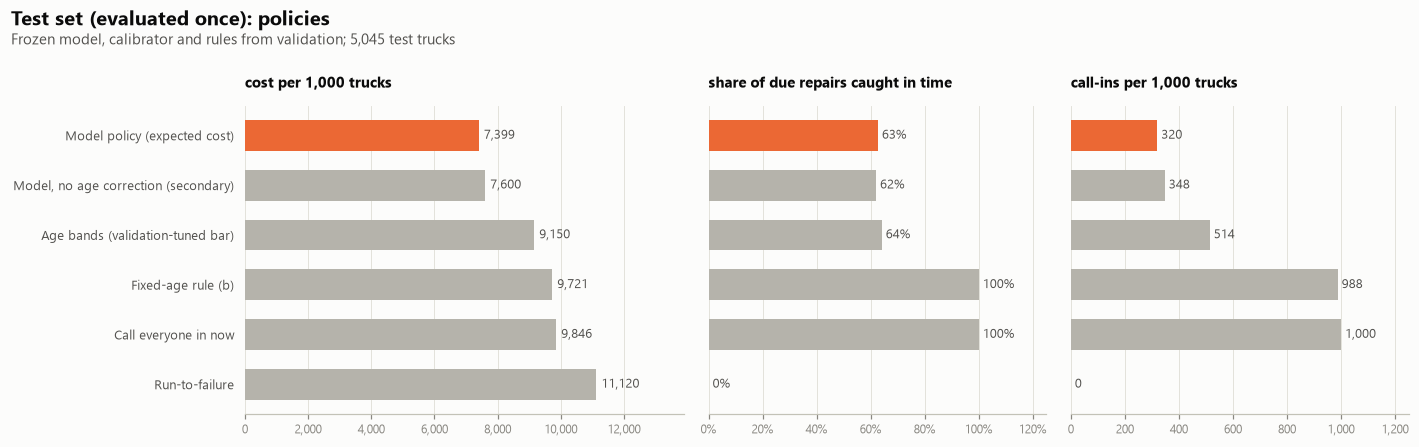

,validation,test
Run-to-failure,"11,375","11,120"
Call everyone in now,"9,823","9,846"
Fixed-age rule (b),"9,702","9,721"
Age bands (validation-tuned bar),"8,109","9,150"
Model policy (expected cost),"6,538","7,399"
"Model, no age correction (secondary)",NaN,"7,600"


In [14]:
both = pd.concat({"validation": val_table.cost_per_1000, "test": test_table.cost_per_1000}, axis=1)
policy_bars(test_table, "Test set (evaluated once): policies",
            "Frozen model, calibrator and rules from validation; 5,045 test trucks", "04_policies_test")
pd.set_option("display.float_format", "{:,.0f}".format)
both

**Interpretation.**

- **The policy holds on test: 7,399 per 1,000 trucks**, against 9,846 for calling everyone in (−25%), 9,721 for the fixed-age rule (−24%), 9,150 for the age bands (−19%) and 11,120 for run-to-failure (−33%). The bootstrap 95% intervals for these savings all exclude zero; the model is cheaper in every one of the 4,000 resamples. Saving vs calling everyone in: 1,214–3,665 per 1,000; vs the fixed-age rule: 1,094–3,529.
- **The policy is weaker than on validation** (6,538): it calls in fewer trucks (320 vs 404 per 1,000) and catches 89 of 142 due repairs (63%, vs 74%), missing 53. Some of that drop is expected: the validation number was picked from six candidates, and 142 due trucks is a small sample.
- **The probabilities transfer well:** mean predicted P(due) 2.9% vs 2.8% observed, and AUC 0.736 vs 0.742 on validation. By age, test also shows fewer due repairs among old trucks (1.2% at ages 300 and over), but less sharply than validation, and the youngest trucks are under-predicted (1.5% predicted vs 2.8% observed below age 100).
- **The age correction turns out to matter little.** Without it the model costs 7,600: only 201 more, with an interval of −466 to +836 that includes zero. The validation-tuned age bands dropped from 8,109 to 9,150 on test, so the age pattern was partly specific to validation. **The headline result does not depend on it**: the model's value comes from specs and usage.

## 7. Illustrative SEK and downtime (test results re-expressed)

The cost matrix is in **relative units**. To give a feel for money and uptime, the test results are
translated with assumptions that are **illustrative, not data**. Each is a parameter to change:

| Assumption (illustrative) | Value | Reasoning |
|---|---|---|
| SEK per cost unit | 1,000 | an unnecessary call-in (10 units) ≈ SEK 10,000: a planned workshop visit incl. lost revenue |
| Downtime per breakdown (missed or late repair) | 24 h | unplanned stop, towing, waiting for parts and a workshop slot |
| Downtime per planned workshop visit | 4 h | booked slot, parts ready |

Downtime per 1,000 trucks = (missed + late repairs) × 24 h + call-ins × 4 h (every call-in, needed
or not, takes the truck off the road for a planned visit).

In [15]:
SEK_PER_UNIT = 1_000        # illustrative
BREAKDOWN_HOURS = 24        # illustrative
VISIT_HOURS = 4             # illustrative


def per_1000(table, n):
    out = pd.DataFrame(index=table.index)
    out["cost_units_per_1000"] = table.cost_per_1000
    out["SEK_per_1000_trucks (illustrative)"] = table.cost_per_1000 * SEK_PER_UNIT
    breakdowns = (table.missed + table.late) * 1000 / n
    out["breakdowns_per_1000"] = breakdowns
    out["downtime_hours_per_1000 (illustrative)"] = breakdowns * BREAKDOWN_HOURS + table.call_ins_per_1000 * VISIT_HOURS
    return out


money = per_1000(test_table, len(y_te))
ref = money.loc["Call everyone in now"]
money["SEK saved vs call-everyone, per 1,000 trucks"] = ref["SEK_per_1000_trucks (illustrative)"] - money["SEK_per_1000_trucks (illustrative)"]
money["downtime hours saved vs call-everyone"] = ref["downtime_hours_per_1000 (illustrative)"] - money["downtime_hours_per_1000 (illustrative)"]
money.round(0)

,cost_units_per_1000,SEK_per_1000_trucks (illustrative),breakdowns_per_1000,downtime_hours_per_1000 (illustrative),"SEK saved vs call-everyone, per 1,000 trucks",downtime hours saved vs call-everyone
Run-to-failure,"11,120","11,119,921",28,676,"-1,274,331","3,324"
Call everyone in now,"9,846","9,845,590",0,"4,000",0,0
Fixed-age rule (b),"9,721","9,720,714",0,"3,950","124,876",50
Age bands (validation-tuned bar),"9,150","9,149,851",10,"2,299","695,738","1,701"
Model policy (expected cost),"7,399","7,399,009",11,"1,533","2,446,581","2,467"
"Model, no age correction (secondary)","7,600","7,599,604",11,"1,648","2,245,986","2,352"


In [16]:
# How the model's downtime result depends on the two hour assumptions (vs calling everyone in).
m, c = test_table.loc["Model policy (expected cost)"], test_table.loc["Call everyone in now"]
nn = len(y_te)
grid = pd.DataFrame(
    {f"visit {v} h": {f"breakdown {b} h": ((c.missed + c.late) * b / nn * 1000 + c.call_ins_per_1000 * v)
                      - ((m.missed + m.late) * b / nn * 1000 + m.call_ins_per_1000 * v)
                      for b in [12, 24, 48, 96]} for v in [2, 4, 8]})
print("Downtime hours saved per 1,000 trucks by the model policy vs calling everyone in (illustrative):")
grid.round(0)

Downtime hours saved per 1,000 trucks by the model policy vs calling everyone in (illustrative):


,visit 2 h,visit 4 h,visit 8 h
breakdown 12 h,"1,234","2,593","5,313"
breakdown 24 h,"1,108","2,467","5,187"
breakdown 48 h,856,"2,215","4,935"
breakdown 96 h,351,"1,711","4,431"


**Interpretation (illustrative assumptions, not data).** All figures are per 1,000 trucks for one planning decision each, covering the next 48 time steps; they are not annual figures.

- **Money:** at SEK 1,000 per cost unit, the model policy costs about SEK 7.4 million per 1,000 trucks, against SEK 9.8 million for calling everyone in and SEK 11.1 million for run-to-failure. That saves about **SEK 2.4 million** vs calling everyone in. The SEK figure is simply the cost result scaled, so it moves one-to-one with the assumed SEK per unit.
- **Downtime:** the model policy needs about 1,500 hours per 1,000 trucks, against 4,000 for calling everyone in: **about 2,500 hours saved**. That comes from roughly 680 fewer workshop visits per 1,000 trucks, at the price of 11 breakdowns. The saving stays positive across the whole grid of assumptions (350–5,300 hours).
- **Downtime and cost can disagree:** measured in hours alone, run-to-failure has the *least* downtime (about 680 hours: 28 breakdowns × 24 h, no visits). The cost matrix prices a breakdown far above its hours (towing, damage, missed deliveries), and that is why the policy is optimised on cost and reports downtime as a secondary view.

## 8. Test snapshot: the service list

The test set is treated as **today's fleet**: one row per truck with its risk, recommended action,
expected saving of calling it in, and a priority rank (highest expected saving first). For trucks the
policy calls in, the **top 3 drivers** of their risk score are added (SHAP, as in notebook 03: the
calibrated log-odds of a repair due within 48 steps; permutation explainer, background of 20 test
trucks). The actual class is included *after* the evaluation above, for the dashboard's model-quality page.
Written to `data/processed/test_service_list.csv`.

In [17]:
d_te = test_pols["Model policy (expected cost)"]
ec_te = expected_cost(P_te)
service = pd.DataFrame({
    "vehicle_id": test.vehicle_id, "age_time_step": age_te,
    **{c: test[c] for c in SPEC_COLS},
    **{f"p{k}": P_te[:, k] for k in CLASSES},
    "p_due_within_48": 1 - P_te[:, 0],
    "recommended_action": d_te, "recommended_label": [ACTIONS[a] for a in d_te],
    "expected_saving_if_called_in": ec_te[:, 0] - ec_te[:, 4],
    "actual_class": y_te,
})
service["priority_rank"] = service.expected_saving_if_called_in.rank(ascending=False, method="first").astype(int)

params = np.array(frozen["calibrator_params"])


def risk_log_odds(M):
    p = artifact["models"]["hist_gb"].predict_proba(M)
    return due_log_odds(apply_calibrator(np.log(np.clip(p, 1e-9, 1)), M[:, AGE_IDX], params, True))


call_idx = np.flatnonzero(d_te > 0)
bg = X_te[rng.choice(len(X_te), 20, replace=False)]
t0 = time.time()
sv = shap.PermutationExplainer(risk_log_odds, shap.maskers.Independent(bg, max_samples=20))(
    X_te[call_idx], max_evals=2 * X_te.shape[1] + 1, silent=True)
print(f"SHAP for {len(call_idx):,} called-in trucks in {time.time() - t0:,.0f} s")
names = [pretty(f) for f in INPUTS]
for r in (1, 2, 3):
    service[f"driver_{r}"] = ""
    service[f"driver_{r}_effect"] = ""
for row, i in enumerate(call_idx):
    for r, j in enumerate(np.argsort(-np.abs(sv.values[row]))[:3], 1):
        service.loc[i, f"driver_{r}"] = names[j]
        service.loc[i, f"driver_{r}_effect"] = "raises risk" if sv.values[row, j] > 0 else "lowers risk"
service = service.sort_values("priority_rank")
service.round(6).to_csv(PROCESSED / "test_service_list.csv", index=False)
service.head(10)[["priority_rank", "vehicle_id", "age_time_step", "p_due_within_48", "recommended_label",
                  "expected_saving_if_called_in", "driver_1", "driver_2", "driver_3"]]

SHAP for 1,615 called-in trucks in 521 s


,priority_rank,vehicle_id,age_time_step,p_due_within_48,recommended_label,expected_saving_if_called_in,driver_1,driver_2,driver_3
4372,1,29171,144,1,Call in now,298,"histogram 158, share in top 2 bins (last 5 rea...","counter 666, change over last 5 readouts",age (time_step)
1574,2,10384,159,1,Call in now,249,"counter 666, rate since previous readout",Spec 7,age (time_step)
1853,3,12298,134,1,Call in now,235,Spec 1,age (time_step),span of last 5 readouts
1639,4,10841,190,1,Call in now,232,"histogram 158, share in top 2 bins (last 5 rea...","counter 666, change over last 5 readouts",Spec 1
1520,5,9912,167,0,Call in now,209,"histogram 158, share in top 2 bins (last 5 rea...",Spec 7,age (time_step)
3874,6,25924,231,0,Call in now,198,"counter 309, level",Spec 7,"histogram 158, share in top 2 bins (last 5 rea..."
1678,7,11101,182,1,Call in now,191,Spec 7,"histogram 158, share in top 2 bins (last 5 rea...","counter 666, rate since previous readout"
4366,8,29092,142,0,Call in now,180,age (time_step),Spec 7,"counter 666, rate since previous readout"
4211,9,28098,187,0,Call in now,150,age (time_step),Spec 1,Spec 7
3687,10,24705,243,0,Call in now,136,"histogram 158, share in top 2 bins (last 5 rea...",Spec 7,"counter 100, level"


In [18]:
counts = service.recommended_label.value_counts().reindex([ACTIONS[k] for k in [4, 3, 2, 1, 0]], fill_value=0)
print("Test fleet snapshot, trucks per recommended action:")
print(counts.to_string())
top_drivers = pd.concat([service[f"driver_{r}"] for r in (1, 2, 3)]).replace("", np.nan).dropna().value_counts().head(10)
print("\nMost frequent drivers among called-in trucks (top-3 mentions):")
top_drivers

Test fleet snapshot, trucks per recommended action:
recommended_label
Call in now             1554
Book within 12 steps      59
Book within 24 steps       2
Plan within 48 steps       0
No action               3430

Most frequent drivers among called-in trucks (top-3 mentions):


age (time_step)                                  1069
Spec 1                                           1020
Spec 7                                           1001
counter 666, level                                229
counter 837, level                                216
counter 309, level                                167
histogram 167, mean bin (lifetime)                162
counter 100, level                                148
histogram 291, share in top 2 bins (lifetime)     104
histogram 291, total count                         85
Name: count, dtype: int64

In [19]:
# Small tables for Power BI.
pc = pd.concat([val_table.assign(split="validation"), test_table.assign(split="test")]).rename_axis("policy").reset_index()
pc.round(4).to_csv(PROCESSED / "policy_comparison.csv", index=False)
sens.round(4).to_csv(PROCESSED / "miss_cost_sensitivity.csv", index=False)
cap.round(4).to_csv(PROCESSED / "capacity_curve.csv", index=False)
boot_table.round(2).to_csv(PROCESSED / "test_bootstrap.csv")
print("wrote policy_comparison.csv, miss_cost_sensitivity.csv, capacity_curve.csv, test_bootstrap.csv, test_service_list.csv")

wrote policy_comparison.csv, miss_cost_sensitivity.csv, capacity_curve.csv, test_bootstrap.csv, test_service_list.csv


## 9. Findings

1. **The risk-based policy cuts the cost of Component X repairs by a quarter on unseen trucks.** On the untouched test set it costs **7,399 per 1,000 trucks**, against 9,846 for calling every truck in, 9,721 for the fixed-age rule and 11,120 for run-to-failure. The bootstrap intervals exclude zero against every baseline. It calls in 32% of the fleet and catches 63% of due repairs in time (illustratively: about SEK 2.4 million and 2,500 downtime hours saved per 1,000 trucks vs calling everyone in).

2. **The value is concentrated in a few call-ins.** With workshop room for only 10% of the fleet, ranking trucks by expected saving catches 36% of due repairs and already beats calling everyone in; it delivers two thirds of the total saving (validation). "Oldest first", the intuitive rule, does worse than picking trucks at random.

3. **The result is robust within limits.** It survives a breakdown cost up to about 2× the expert matrix with today's decisions (about 2.8× if re-optimised). Beyond that, calling everyone in is as good. The validation-learned age correction added little on test (201 per 1,000 trucks, not significant), so the policy rests on spec and usage signals, not on a quirk of one split.

**Limitations.** The data is anonymized and partly perturbed (SOURCES.md), and `time_step` is operating time, not calendar time. Test labels describe one snapshot per truck, and only 142 test trucks had a repair due. SEK and downtime are illustrative. The cost matrix's relative units are the only real money signal.